# The deconstructed wavelet cascade: proof of exactness, and what it buys

Decomposing a long record in pieces sounds simple: split the signal, take the
wavelet coefficients of each piece, save them, then restart the decomposition
from the concatenated approximation (cA). Done naively, **the coefficients do
not match** the ones you would get decomposing the whole record at once — the
wavelet filter looks across the cut, and the default `pywt` boundary mode
even changes the number of coefficients per level.

`fluxscale.core.cascade` implements the *deconstructed cascade* correctly:

1. **Stage 1** — each chunk is read with a margin of *real* neighbouring
   samples, decomposed with `mode='periodization'` down to `split_level`,
   and the boundary-contaminated coefficients are trimmed before storing.
2. **Stage 2** — the concatenated approximation (the *carry*, a factor
   `2**split_level` shorter than the record) is decomposed in memory down to
   any depth.

This notebook first **proves** the result is *exactly* the plain
`pywt.wavedec` of the full record, then illustrates **why** the margins make
it work, and finally **what it buys**: fluxes at scales far beyond the
averaging window, over records that never fit in memory.

In [1]:
import shutil
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt

# run against the local repository (works from sample/ or the repo root)
repo = Path.cwd()
if not (repo / 'fluxscale').exists():
    repo = repo.parent
sys.path.insert(0, str(repo))
from fluxscale.core import cascade

WAVELET = 'db6'
FS = 20.0                                # sampling rate [Hz]
FILTER_LEN = pywt.Wavelet(WAVELET).dec_len
rng = np.random.default_rng(42)
workdir = Path(tempfile.gettempdir()) / 'fluxscale_cascade_demo'
workdir.mkdir(exist_ok=True)
print(f"wavelet {WAVELET} (filter length {FILTER_LEN}), fs = {FS:g} Hz")

c:\Users\phherigcoimb\Anaconda3\envs\wavec\Lib\site-packages\pywt\_cwt.py:19: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.1)
  import scipy.fft


wavelet db6 (filter length 12), fs = 20 Hz


## Part A — the cascade equals the full transform, exactly

A ~7 h record at 20 Hz, decomposed to level 14 (scale ≈ 14 min) two ways:

* **full**: one `pywt.wavedec` call on the whole record;
* **cascade**: 32 chunks of ~14 min through the store
  (`split_level=6`, margins handled internally), then `cascade_finish`.

The store keeps `float64` here to show bit-for-bit agreement (the default
archive dtype is `float32`, which adds only a ~1e-8 relative rounding).

In [2]:
N, SPLIT, LEVEL = 2**19, 6, 14
x = np.cumsum(rng.standard_normal(N))
x -= x.mean()

full = pywt.wavedec(x, WAVELET, level=LEVEL, mode='periodization')

store = cascade.CascadeStore.create(
    workdir / 'exactness.zarr', ['x'], n_samples=N, fs=FS, wavelet=WAVELET,
    split_level=SPLIT, chunk_size=2**14, t0='2022-05-13T00:00:00',
    details_dtype='float64', overwrite=True)
cascade.cascade_run(store, {'x': x})
cascade.cascade_finish(store, level=LEVEL)

rows = []
for name, ref in zip([f'cA{LEVEL}'] + [f'cD{j}' for j in range(LEVEL, 0, -1)],
                     full):
    arr = 'cA' if name.startswith('cA') else f'cD{int(name[2:]):02d}'
    got = store['x'][arr][:]
    rows.append({'coefficients': name, 'count': ref.size,
                 'max |cascade − full|': float(np.max(np.abs(got - ref)))})
table = pd.DataFrame(rows)
worst = table['max |cascade − full|'].max()
print(f"worst deviation over all {LEVEL + 1} coefficient sets: {worst:.2e}")
assert worst < 1e-12
table

worst deviation over all 15 coefficient sets: 5.68e-14


,coefficients,count,max |cascade − full|
0,cA14,32,0.000000e+00
1,cD14,32,0.000000e+00
2,cD13,64,0.000000e+00
3,cD12,128,0.000000e+00
4,cD11,256,0.000000e+00
5,cD10,512,0.000000e+00
6,cD9,1024,0.000000e+00
7,cD8,2048,0.000000e+00
8,cD7,4096,0.000000e+00
9,cD6,8192,1.421085e-14


Every coefficient of every level is **identical** to the single-call
transform. That is the whole point: the cascade is not an approximation —
it is the same transform computed in bounded memory.

### What goes wrong without the machinery

Split the record in two and decompose each half separately (no margins).
Periodization then wraps each half onto *itself*: every coefficient whose
filter support crosses a cut — the junction or the record ends — is computed
from the wrong samples:

20 of 16384 coefficients are wrong (0.1%) — and with the default mode='symmetric' the pieces do not even have matching lengths:
  full cD1: 262149 coefficients; two pieces concatenated: 262154


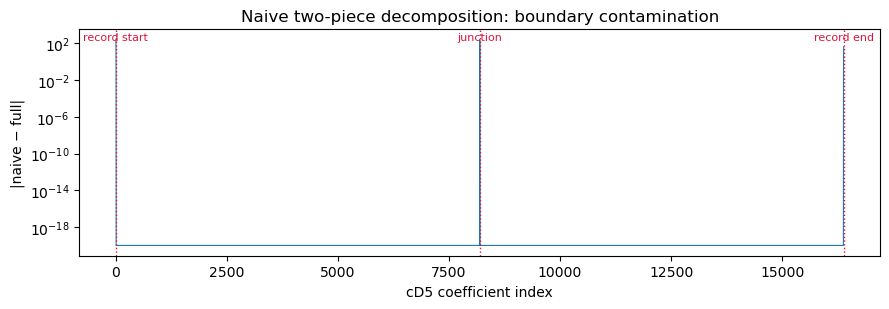

In [3]:
J_SHOW = 5                                   # look at detail level 5
h1 = pywt.wavedec(x[:N // 2], WAVELET, level=SPLIT, mode='periodization')
h2 = pywt.wavedec(x[N // 2:], WAVELET, level=SPLIT, mode='periodization')
naive = np.concatenate([h1[SPLIT - J_SHOW + 1], h2[SPLIT - J_SHOW + 1]])
ref = full[LEVEL - J_SHOW + 1]
err = np.abs(naive - ref)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.semilogy(err + 1e-20, lw=.8)
for pos, lab in [(0, 'record start'), (naive.size // 2, 'junction'),
                 (naive.size - 1, 'record end')]:
    ax.axvline(pos, color='crimson', ls=':', lw=1)
    ax.annotate(lab, (pos, err.max()), ha='center', fontsize=8, color='crimson')
ax.set(xlabel=f'cD{J_SHOW} coefficient index',
       ylabel='|naive − full|',
       title='Naive two-piece decomposition: boundary contamination')
plt.tight_layout()

n_bad = int((err > 1e-12).sum())
print(f"{n_bad} of {err.size} coefficients are wrong "
      f"({100 * n_bad / err.size:.1f}%) — and with the default "
      f"mode='symmetric' the pieces do not even have matching lengths:")
print(f"  full cD1: {pywt.wavedec(x, WAVELET, level=SPLIT)[-1].size} coefficients; "
      f"two pieces concatenated: "
      f"{2 * pywt.wavedec(x[:N // 2], WAVELET, level=SPLIT)[-1].size}")

## Part B — why the margins fix it

A level-*j* detail coefficient depends on roughly `(L−1)·2**j` neighbouring
samples (`L` = filter length, 12 for db6). So a chunk decomposed to
`split_level` needs its neighbours' data over that reach — no more. The
cascade therefore pads each chunk with `margin` **real** samples per side,
decomposes, and throws the contaminated edge coefficients away.

Sweep the margin from 0 upward and watch the error collapse to machine
precision once the margin covers the deepest stage-1 filter support:

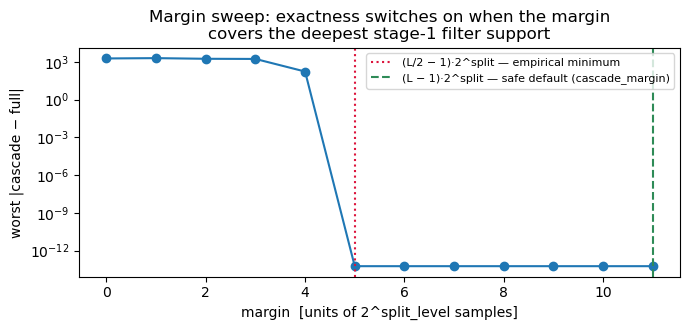

In [4]:
full_split = pywt.wavedec(x, WAVELET, level=SPLIT, mode='periodization')


def cascade_error(margin):
    det = {j: [] for j in range(1, SPLIT + 1)}
    car = []
    for s in range(0, N, N // 2):
        padded = x[np.arange(s - margin, s + N // 2 + margin) % N]
        d, c = cascade.chunk_wavedec(padded, margin, SPLIT, WAVELET)
        car.append(c)
        for j in d:
            det[j].append(d[j])
    worst = np.max(np.abs(np.concatenate(car) - full_split[0]))
    for j in range(1, SPLIT + 1):
        worst = max(worst, np.max(np.abs(
            np.concatenate(det[j]) - full_split[SPLIT - j + 1])))
    return worst


ks = np.arange(0, FILTER_LEN)
errs = [cascade_error(int(k) * 2**SPLIT) for k in ks]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(ks, np.array(errs) + 1e-18, 'o-')
ax.axvline(FILTER_LEN / 2 - 1, color='crimson', ls=':',
           label='(L/2 − 1)·2^split — empirical minimum')
ax.axvline(FILTER_LEN - 1, color='seagreen', ls='--',
           label='(L − 1)·2^split — safe default (cascade_margin)')
ax.set(xlabel='margin  [units of 2^split_level samples]',
       ylabel='worst |cascade − full|',
       title='Margin sweep: exactness switches on when the margin\n'
             'covers the deepest stage-1 filter support')
ax.legend(fontsize=8)
plt.tight_layout()

The module's default (`cascade_margin` = `(L−1)·2**split_level`) sits safely
right of the cliff, and costs almost nothing: at `split_level=12`
(3.4 min scale) it is ~38 min of data per chunk side.

**Stage 2 needs no margins at all.** `wavedec` is recursive — levels
`split_level+1 … level` of the full transform *are* the transform of the
level-`split_level` approximation. Once stage 1 reproduces the carry
exactly, everything deeper is automatically exact (Part A already proved
levels 7–14 this way).

## Part C — what the cascade buys

Per variable and year of 20 Hz data (float32):

| representation | size |
|---|---|
| raw signal (6.3×10⁸ samples) | ~2.5 GB |
| **all DWT coefficients (any depth, periodized)** | **~2.5 GB** |
| per-level reconstructions, 25 levels (the old dense layout) | ~65 GB |

Memory during stage 1 is set by the chunk size, not the record length — a few
hundred MB at the default chunk — and the run is resumable. The payoff:
**flux contributions at scales far beyond the 30-min averaging window**.

Demonstration: a ~29 h record of `w` and `co2` sharing (i) fast turbulent
transport and (ii) a slow correlated oscillation with a **1.8 h period** —
a covariance contribution completely invisible to 30-min block averaging:

Record (2097152 samples) is not a whole number of 36000-sample windows; the tail is dropped.


total covariance          : -0.4447
captured below 30 min     : -0.3999
missed by a 30-min cutoff : 10% (the injected slow transport)


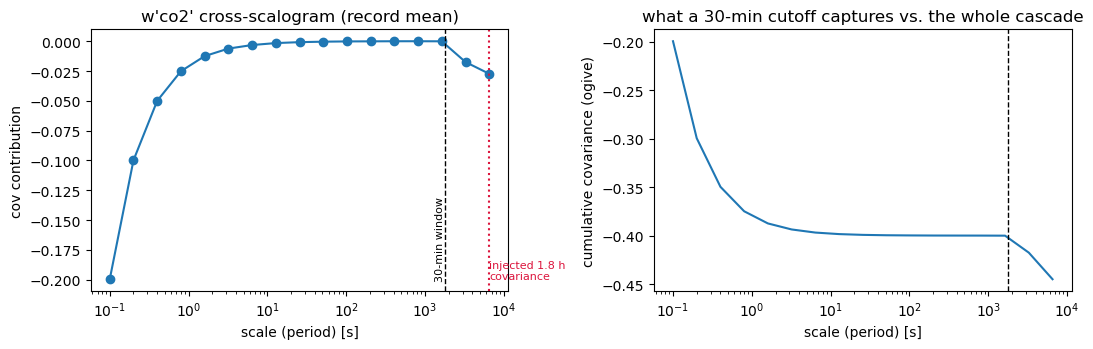

In [5]:
N2, SPLIT2 = 2**21, 9                       # ~29 h at 20 Hz; stage-1 scale 26 s
t = np.arange(N2) / FS
period = 2**17 / FS                          # 6554 s ≈ 1.8 h
slow = np.sin(2 * np.pi * t / period)

nw = rng.standard_normal(N2)                 # shared turbulent part
w_ = nw + 0.15 * slow
co2_ = -0.4 * nw + rng.standard_normal(N2) - 0.6 * slow

store2 = cascade.CascadeStore.create(
    workdir / 'lowfreq.zarr', ['w', 'co2'], n_samples=N2, fs=FS,
    wavelet=WAVELET, split_level=SPLIT2, chunk_size=2**18,
    t0='2022-05-13T00:00:00', details_dtype='float64', overwrite=True)
cascade.cascade_run(store2, {'w': w_, 'co2': co2_})
cascade.cascade_finish(store2)               # to dwt_max_level (here: 17)

ds = cascade.scale_covariance(store2, 'w', 'co2', window=1800)
spec = ds['wco2'].mean('TIMESTAMP')
periods = 1.0 / spec.natural_frequency

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.semilogx(periods, spec, 'o-')
ax1.axvline(1800, color='k', ls='--', lw=1)
ax1.axvline(period, color='crimson', ls=':', lw=1.5)
ax1.annotate('30-min window', (1800, spec.min()), rotation=90,
             fontsize=8, ha='right')
ax1.annotate('injected 1.8 h\ncovariance', (period, spec.min()),
             fontsize=8, color='crimson', ha='left')
ax1.set(xlabel='scale (period) [s]', ylabel="cov contribution",
        title="w'co2' cross-scalogram (record mean)")

ogive = spec.sortby('natural_frequency', ascending=False).cumsum()
ax2.semilogx(1 / ogive.natural_frequency, ogive, '-')
ax2.axvline(1800, color='k', ls='--', lw=1)
ax2.set(xlabel='scale (period) [s]', ylabel='cumulative covariance (ogive)',
        title='what a 30-min cutoff captures vs. the whole cascade')
plt.tight_layout()

total = float(spec.sum() + ds['wco2_lf'].mean())
fast = float(spec.where(spec.natural_frequency > 1 / 1800, 0.0).sum())
print(f"total covariance          : {total:+.4f}")
print(f"captured below 30 min     : {fast:+.4f}")
print(f"missed by a 30-min cutoff : {100 * (total - fast) / total:.0f}% "
      f"(the injected slow transport)")

The cross-scalogram resolves the injected 1.8 h covariance at exactly its
scale, and the ogive shows a 30-min cutoff would miss it entirely — that
missing fraction is what the cascade exists to measure.

### Gaps are tracked, not hidden

Real records have holes. Stage 1 interpolates them (so the transform stays
defined) and records, for every coefficient of every level, the fraction of
gap-filled samples under its support — the `qc` arrays:

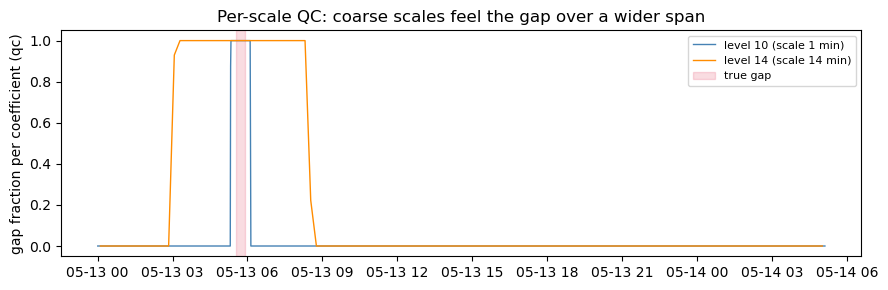

In [6]:
co2_gappy = co2_.copy()
gap = slice(400_000, 424_000)                        # a 20-min gap
co2_gappy[gap] = np.nan

store3 = cascade.CascadeStore.create(
    workdir / 'gaps.zarr', ['co2'], n_samples=N2, fs=FS, wavelet=WAVELET,
    split_level=SPLIT2, chunk_size=2**18, t0='2022-05-13T00:00:00',
    details_dtype='float64', overwrite=True)
cascade.cascade_run(store3, {'co2': co2_gappy})
cascade.cascade_finish(store3)

fig, ax = plt.subplots(figsize=(9, 3))
for j, color in [(10, 'steelblue'), (14, 'darkorange')]:
    qc = cascade.open_level(store3, 'co2', j, qc=True)
    ax.plot(qc.TIMESTAMP, qc, color=color, lw=1,
            label=f'level {j} (scale {2**j / FS / 60:.0f} min)')
ax.axvspan(np.datetime64('2022-05-13T00:00:00') + np.timedelta64(int(gap.start / FS), 's'),
           np.datetime64('2022-05-13T00:00:00') + np.timedelta64(int(gap.stop / FS), 's'),
           color='crimson', alpha=.15, label='true gap')
ax.set(ylabel='gap fraction per coefficient (qc)',
       title='Per-scale QC: coarse scales feel the gap over a wider span')
ax.legend(fontsize=8)
plt.tight_layout()

## Summary

* **Exact**: cascade coefficients ≡ `pywt.wavedec` of the whole record
  (Part A; enforced by `tests/test_cascade.py` down to 1e-10).
* **Why it works**: real-data margins cover the filter support, trimmed
  after the transform; stage 2 is exact by the recursion of `wavedec`
  (Part B).
* **What it buys**: any-depth scales with bounded memory, a
  coefficient archive the size of the raw data, per-scale fluxes via
  `scale_covariance`, per-scale gap QC (Part C).

Constraints to remember: `n_samples` and `chunk_size` must be multiples of
`2**split_level`; pick the record span accordingly (pad once, globally, if
needed). Details are stored `float32` by default (`details_dtype='float64'`
for bit-exactness); the carry is always `float64`.

In [7]:
shutil.rmtree(workdir, ignore_errors=True)   # tidy up the temporary stores
print('demo stores removed')

demo stores removed
